## 檢視是否能夠正常使用 GPU

In [2]:
!nvidia-smi

Thu Oct 22 15:17:11 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   61C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 掛載雲端硬碟到 /content 當中

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 如果一直被提醒 GPU 沒有使用，可能的解法

In [ ]:
import torch
import time
from IPython.display import clear_output

while True:
    # 清除輸出，避免畫面過長
    clear_output(wait=True)

    # 1. 檢查 GPU 是否可用
    print(torch.cuda.is_available())  # 回傳 True 代表可用，False 代表不可用

    # 2. 取得可用的 GPU 數量
    print(torch.cuda.device_count())

    # 3. 取得目前 GPU 的名稱
    if torch.cuda.is_available():
        print(torch.cuda.get_device_name(0))

    # 4. 設定預設使用的裝置 (Device)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(device)

    time.sleep(30)  # 每隔 30 秒檢查一次

In [5]:
import pandas as pd

df = pd.read_csv("./homework1/data.csv")

print(df.head())
print(df.columns.tolist())
print(df["emotion"].value_counts())
print(df.isna().sum())

                    text emotion
0              你要不要去吃午餐？    平淡語氣
1             誒誒誒！我甄選上了！    開心語調
2     我幾天身體好像有點不太舒服，肚子好痛    悲傷語調
3  我的小專題組員都不做事，幹!超後悔跟他一組    憤怒語調
4       他們是不是吵架了？不會打起來吧？    平淡語氣
['text', 'emotion']
emotion
平淡語氣    705
開心語調    592
關切語調    560
憤怒語調    527
驚奇語調    499
悲傷語調    486
厭惡語調    404
疑問語調    386
Name: count, dtype: int64
text       0
emotion    0
dtype: int64


In [6]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


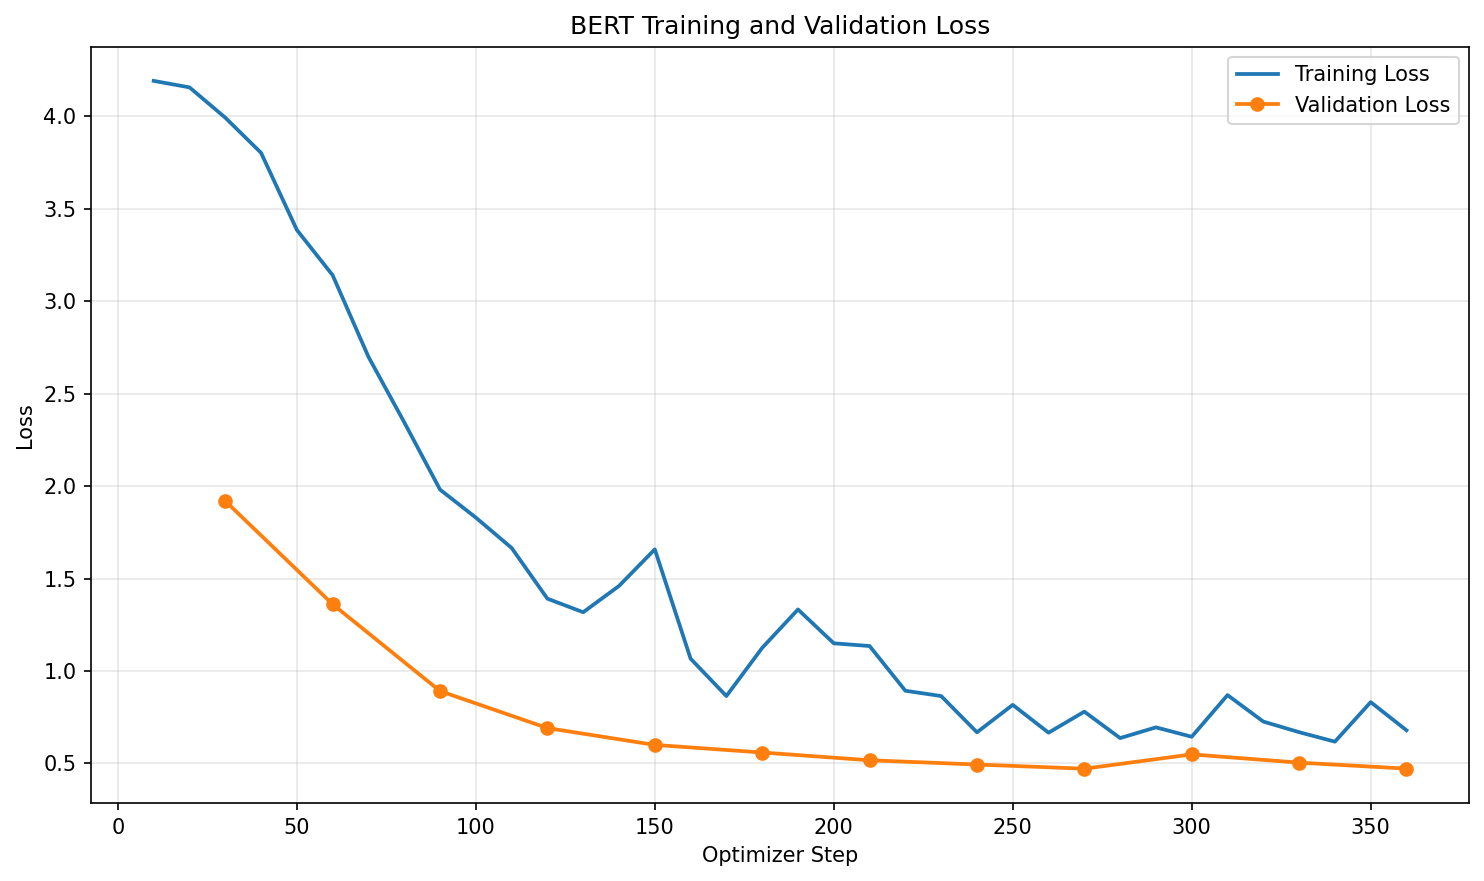

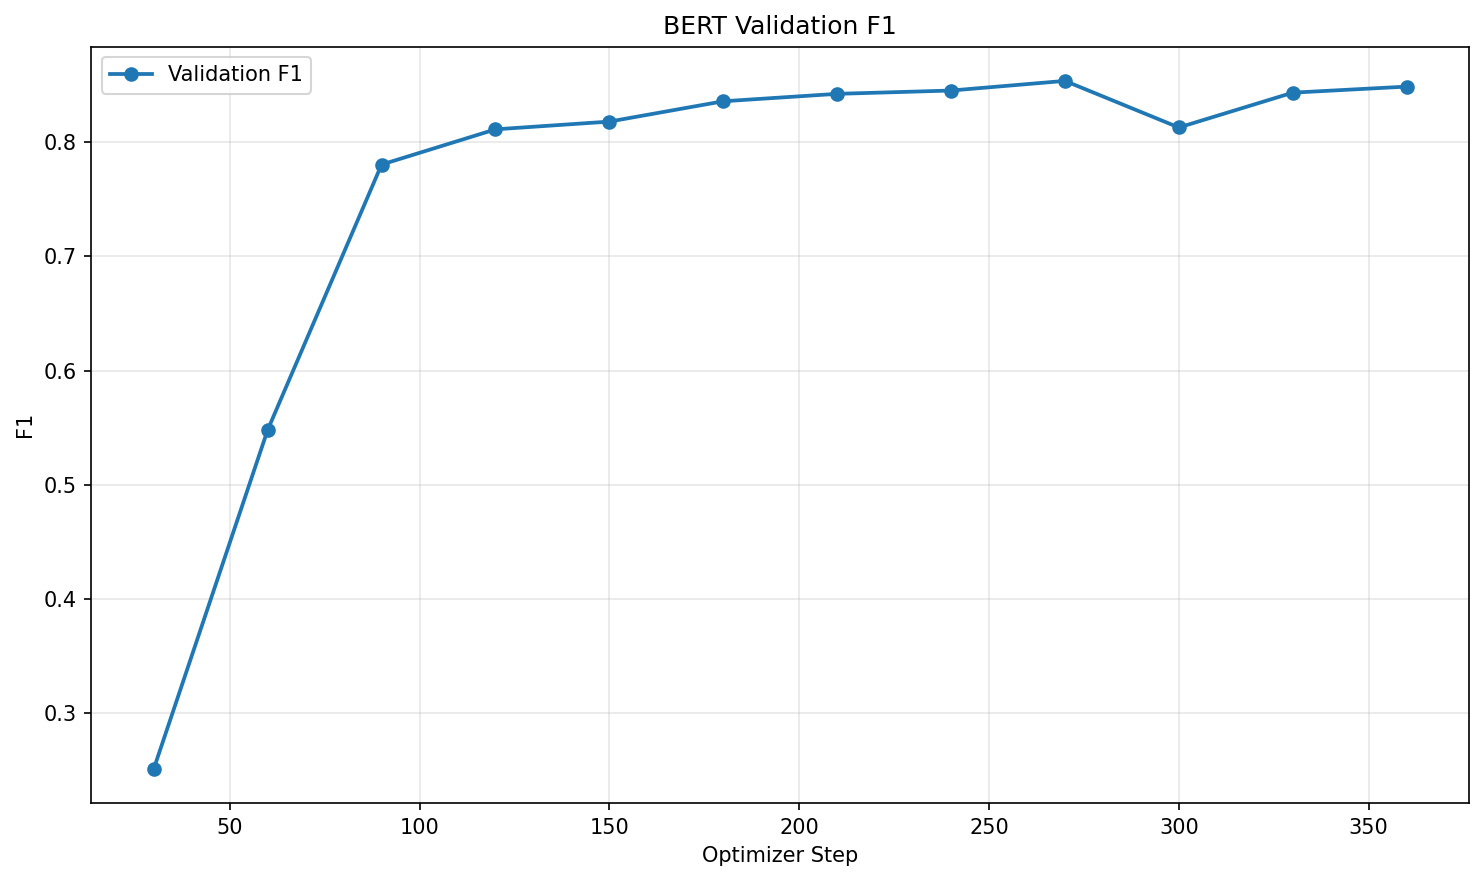

In [7]:
from pathlib import Path
from IPython.display import display, Image

model_dir = Path("/content/homework1/output/bert_emotion_clf")

for name in ["loss_curve.png", "f1_curve.png"]:
    image_path = model_dir / name

    if image_path.is_file():
        display(Image(filename=str(image_path)))
    else:
        print(f"尚未找到：{image_path}")

In [9]:
from importlib.metadata import version

packages = [
    "torch",
    "transformers",
    "datasets",
    "accelerate",
    "scikit-learn",
    "pandas",
    "numpy",
    "matplotlib",
]

for package in packages:
    print(f"{package}=={version(package)}")

torch==2.11.0+cu130
transformers==5.20.1
datasets==4.8.5
accelerate==1.15.0
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
matplotlib==3.10.0


In [10]:
import json
from pathlib import Path

model_dir = Path("/content/homework1/output/bert_emotion_clf")

with (model_dir / "trainer_state.json").open(
    "r", encoding="utf-8"
) as file:
    state = json.load(file)

best_checkpoint = state["best_model_checkpoint"]
best_step = int(Path(best_checkpoint).name.split("-")[-1])

print("最佳 checkpoint：", best_checkpoint)

for record in state["log_history"]:
    if record.get("step") == best_step and "eval_loss" in record:
        print("驗證步數：", record["step"])

        for key in ["eval_loss", "eval_accuracy", "eval_f1"]:
            if key in record:
                print(f"{key}：{record[key]:.4f}")

最佳 checkpoint： /content/homework1/output/bert_emotion_clf/checkpoint-270
驗證步數： 270
eval_loss：0.4716
eval_accuracy：0.8570
eval_f1：0.8534


In [11]:
import shutil
from pathlib import Path

source = Path("/content/homework1")
backup = Path("/content/drive/MyDrive/nlp_homework1_backup")

if not backup.parent.is_dir():
    raise FileNotFoundError("請先掛載 Google Drive，再執行備份。")

shutil.copytree(source, backup, dirs_exist_ok=True)

print("已備份到：", backup)

已備份到： /content/drive/MyDrive/nlp_homework1_backup
